# Laboratory 3 homework

In [1]:
import matplotlib.pyplot as plt
import polars as pl
import polars.selectors as cs

DATA_DIR = "data"

## 1. Data reading

- load all 2024 months of taxi rides
- also load taxi zone lookup data
- include only rides starting in 2024 and ending at most at 01.01.2025
- optimize data types, particularly for integers and categorical strings

In [2]:
taxi_zones = pl.scan_csv(
    f"{DATA_DIR}/taxi_zone_lookup.csv",
    schema_overrides={
        "LocationID": pl.UInt16,
        "Borough": pl.Categorical,
        "Zone": pl.Categorical,
        "service_zone": pl.Categorical,
    },
)


def read_taxi_rides() -> pl.LazyFrame:
    taxi_ride_parts = [
        pl.scan_parquet(f"{DATA_DIR}/{month}.parquet").with_columns(
            pl.col("tpep_pickup_datetime").dt.cast_time_unit("ms"),
            pl.col("tpep_dropoff_datetime").dt.cast_time_unit("ms"),
        )
        for month in range(1, 13)
    ]
    return (
        pl.concat(taxi_ride_parts)
        .cast(
            {
                "VendorID": pl.UInt8,
                "passenger_count": pl.UInt8,
                "RatecodeID": pl.UInt8,
                "PULocationID": pl.UInt16,
                "DOLocationID": pl.UInt16,
                "payment_type": pl.UInt8,
                "store_and_fwd_flag": pl.Categorical,
            }
        )
        .filter(
            pl.col("tpep_pickup_datetime").dt.year() == 2024,
            pl.col("tpep_dropoff_datetime").dt.date() <= pl.date(2025, 1, 1),
        )
    )

## 2. Data cleaning and filtering

- fill NULL values in `passengers_count` with 1
- remove rides with zero passengers
- if a ride has over 6 passengers, replace the value with 6
- remove rides lasting over 2 hours
- in all money-related columns, replace values with absolute value to fix negative amounts
- remove rides with over 1000 dollars in any money-related column
- remove rows with values of `RatecodeID` or `VendorID` missing or outside those defined in the data dictionary

In [3]:
MONEY_COLUMNS = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "Airport_fee",
]
VENDORS = {
    1: "Creative Mobile Technologies, LLC",
    2: "Curb Mobility, LLC",
    6: "Myle Technologies Inc",
    7: "Helix",
}
RATE_CODES = {
    1: "Standard rate",
    2: "JFK",
    3: "Newark",
    4: "Nassau or Westchester",
    5: "Negotiated fare",
    6: "Group ride",
}


def clean(taxi_rides: pl.LazyFrame) -> pl.LazyFrame:
    return (
        taxi_rides.with_columns(pl.col("passenger_count").fill_null(1))
        .remove(pl.col("passenger_count") == 0)
        .with_columns(pl.col("passenger_count").clip(1, 6))
        .remove(
            pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime")
            > pl.duration(hours=2)
        )
        .with_columns(pl.col(MONEY_COLUMNS).abs())
        .remove(pl.any_horizontal(pl.col(MONEY_COLUMNS) > 1000))
        .filter(
            pl.col("VendorID").is_in(list(VENDORS)),
            pl.col("RatecodeID").is_in(list(RATE_CODES)),
        )
    )

## 3. Data transformation

- combine payment type values for `"No charge"`, `"Dispute"`, `"Unknown"` and `"Voided trip"` into one type, so we have only credit card, cash, or other
- replace `PULocationID` and `DOLocationID` with borough names by joining taxi zone lookup and removing unnecessary columns
- add boolean variable `is_airport_ride`, true if there is non-zero airport fee
- add boolean variable `is_rush_hour`, rush hours are defined as 6:30–9:30 and 15:30-20:00 during weekdays

In [4]:
PAYMENT_TYPE = pl.Enum(["credit_card", "cash", "other"])

pickup_boroughs = taxi_zones.select("LocationID", pickup_borough="Borough")
dropoff_boroughs = taxi_zones.select("LocationID", dropoff_borough="Borough")


def transform(taxi_rides: pl.LazyFrame) -> pl.LazyFrame:
    pickup_time = pl.col("tpep_pickup_datetime").dt.time()
    return (
        taxi_rides.with_columns(
            pl.col("payment_type").replace_strict(
                {1: "credit_card", 2: "cash"},
                default="other",
                return_dtype=PAYMENT_TYPE,
            )
        )
        .join(pickup_boroughs, left_on="PULocationID", right_on="LocationID")
        .join(dropoff_boroughs, left_on="DOLocationID", right_on="LocationID")
        .drop("PULocationID", "DOLocationID")
        .with_columns(
            pl.col("Airport_fee").gt(0).alias("is_airport_ride"),
            (
                (pl.col("tpep_pickup_datetime").dt.weekday() <= 5)
                & (
                    pickup_time.is_between(pl.time(6, 30), pl.time(9, 30))
                    | pickup_time.is_between(pl.time(15, 30), pl.time(20, 0))
                )
            ).alias("is_rush_hour"),
        )
    )

## 4. Feature extraction

- apply dummy encoding to features:
  - payment type
  - pickup borough
  - dropoff borough
- add integer variables for counting daily events:
  - total number of rides (target variable)
  - number of airport rides
  - number of rush hour rides
- add features aggregating daily rides information:
  - average fare amount
  - median distance
  - sum of total amounts
  - total amount paid by card, cash, and other
  - total congestion surcharge
  - total number of passengers
- add time features:
  - `quarter`
  - `month`
  - `day_of_month`
  - `day_of_week`
  - `is_weekend` (boolean)
- add column `date`, indicating day with given features
- make sure to exclude other columns, unnecessary for machine learning, e.g. IDs, timestamps, unused financial information
- properly name all columns
- save results as `dataset.parquet` file

In [5]:
def column_suffix(name: str) -> str:
    return name.lower().replace(" ", "_").replace("/", "")


BOROUGHS = (
    taxi_zones.select(pl.col("Borough").cast(pl.String).unique().sort())
    .collect()
    .to_series()
    .to_list()
)

dummies = [
    *[
        (pl.col("payment_type") == p).alias(f"payment_type_{p}")
        for p in PAYMENT_TYPE.categories
    ],
    *[
        (pl.col("pickup_borough") == b).alias(f"pickup_borough_{column_suffix(b)}")
        for b in BOROUGHS
    ],
    *[
        (pl.col("dropoff_borough") == b).alias(f"dropoff_borough_{column_suffix(b)}")
        for b in BOROUGHS
    ],
]


def extract_features(taxi_rides: pl.LazyFrame) -> pl.LazyFrame:
    return (
        taxi_rides.with_columns(dummies)
        .with_columns(pl.col("tpep_pickup_datetime").dt.date().alias("date"))
        .group_by("date")
        .agg(
            pl.len().alias("total_rides"),
            pl.col("is_airport_ride").sum().alias("airport_rides"),
            pl.col("is_rush_hour").sum().alias("rush_hour_rides"),
            pl.col("fare_amount").mean().alias("avg_fare_amount"),
            pl.col("trip_distance").median().alias("median_trip_distance"),
            pl.col("total_amount").sum(),
            *[
                pl.col("total_amount")
                .filter(pl.col("payment_type") == p)
                .sum()
                .alias(f"total_amount_{p}")
                for p in PAYMENT_TYPE.categories
            ],
            pl.col("congestion_surcharge").sum().alias("total_congestion_surcharge"),
            pl.col("passenger_count").sum().alias("total_passengers"),
            cs.starts_with(
                "payment_type_", "pickup_borough_", "dropoff_borough_"
            ).sum(),
        )
        .with_columns(
            pl.col("date").dt.quarter().alias("quarter"),
            pl.col("date").dt.month().alias("month"),
            pl.col("date").dt.day().alias("day_of_month"),
            pl.col("date").dt.weekday().alias("day_of_week"),
            pl.col("date").dt.weekday().gt(5).alias("is_weekend"),
        )
        .sort("date")
    )

In [6]:
dataset = read_taxi_rides().pipe(clean).pipe(transform).pipe(extract_features)
dataset.collect().write_parquet(f"{DATA_DIR}/dataset.parquet")

## 5. Data analysis

- print shape
- show top rows
- describe statistics
- print schema
- plot target variable (daily number of rides):
  - histogram of values
  - line plot, date vs number of rides (remember to sort by date)

In [7]:
df = pl.read_parquet(f"{DATA_DIR}/dataset.parquet")
print("shape", df.shape)

shape (366, 36)


In [8]:
df.head()

date,total_rides,airport_rides,rush_hour_rides,avg_fare_amount,median_trip_distance,total_amount,total_amount_credit_card,total_amount_cash,total_amount_other,total_congestion_surcharge,total_passengers,payment_type_credit_card,payment_type_cash,payment_type_other,pickup_borough_bronx,pickup_borough_brooklyn,pickup_borough_ewr,pickup_borough_manhattan,pickup_borough_na,pickup_borough_queens,pickup_borough_staten_island,pickup_borough_unknown,dropoff_borough_bronx,dropoff_borough_brooklyn,dropoff_borough_ewr,dropoff_borough_manhattan,dropoff_borough_na,dropoff_borough_queens,dropoff_borough_staten_island,dropoff_borough_unknown,quarter,month,day_of_month,day_of_week,is_weekend
date,u32,u32,u32,f64,f64,f64,f64,f64,f64,f64,i64,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,i8,i8,i8,i8,bool
2024-01-01,69541,8352,19360,22.184388,2.09,2.1793e6,1.7389e6,384662.67,55778.86,156123.25,109013,52846,14491,2204,60,627,21,59231,93,9235,3,271,559,3785,388,58579,605,5150,31,444,1,1,1,1,false
2024-01-02,71443,9828,30554,21.312124,1.8,2.2095e6,1.7617e6,396334.47,51441.03,160615.0,102927,54034,15387,2022,34,232,20,60126,54,10709,2,266,433,2979,319,62212,432,4651,32,385,1,1,2,2,false
2024-01-03,78399,9140,32924,19.968751,1.72,2.2900e6,1.8242e6,416241.57,49554.25,177985.0,109805,60176,16202,2021,48,301,16,67701,36,9981,1,315,498,3124,282,69273,395,4340,14,473,1,1,3,3,false
2024-01-04,97896,8270,43112,18.68711,1.73,2.7179e6,2.2134e6,444631.77,59823.2,226627.5,134634,77557,17994,2345,42,257,10,88136,39,9026,1,385,596,3089,226,88692,344,4386,14,549,1,1,4,4,false
2024-01-05,97958,7460,40150,18.114238,1.7,2.6451e6,2.1666e6,420694.52,57798.23,227540.0,136260,77801,17697,2460,47,298,8,88955,37,8218,1,394,536,2889,222,89122,342,4220,20,607,1,1,5,5,false


In [9]:
df.describe()

statistic,date,total_rides,airport_rides,rush_hour_rides,avg_fare_amount,median_trip_distance,total_amount,total_amount_credit_card,total_amount_cash,total_amount_other,total_congestion_surcharge,total_passengers,payment_type_credit_card,payment_type_cash,payment_type_other,pickup_borough_bronx,pickup_borough_brooklyn,pickup_borough_ewr,pickup_borough_manhattan,pickup_borough_na,pickup_borough_queens,pickup_borough_staten_island,pickup_borough_unknown,dropoff_borough_bronx,dropoff_borough_brooklyn,dropoff_borough_ewr,dropoff_borough_manhattan,dropoff_borough_na,dropoff_borough_queens,dropoff_borough_staten_island,dropoff_borough_unknown,quarter,month,day_of_month,day_of_week,is_weekend
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""366""",366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2024-07-01 12:00:00""",98868.724044,8978.286885,29516.784153,19.786537,1.703402,2.8673e6,2.4169e6,372238.44194,78113.331175,230202.863443,133730.005464,81015.669399,14922.625683,2930.428962,47.15847,385.060109,15.983607,88142.147541,59.327869,9903.898907,2.52459,312.622951,457.551913,3542.576503,284.52459,88607.368852,482.73224,5020.008197,25.193989,448.76776,2.505464,6.513661,15.756831,3.986339,0.284153
"""std""",null,15190.761579,1715.381363,19423.582497,1.205793,0.102148,453325.507363,420840.409443,36180.807494,17252.194734,37859.553615,18670.136793,13980.249878,1357.151158,553.868388,13.637459,133.636931,7.71263,15100.815305,17.816158,1750.914054,1.677636,57.28745,60.097148,554.097839,73.624208,14601.766093,93.5843,680.723074,6.712333,92.084524,1.119551,3.455958,8.823592,2.006108,null
"""min""","""2024-01-01""",46930.0,3355.0,0.0,16.623276,1.5,1.3081e6,978705.28,240633.43,41303.84,107820.0,73723.0,33594.0,10244.0,1656.0,22.0,167.0,2.0,41627.0,23.0,4814.0,0.0,149.0,312.0,1663.0,122.0,41529.0,260.0,2739.0,9.0,192.0,1.0,1.0,1.0,1.0,0.0
"""25%""","""2024-04-01""",88657.0,7869.0,0.0,18.945217,1.64,2.5439e6,2.1289e6,352425.45,65781.9,203501.0,121081.0,71633.0,14108.0,2566.0,37.0,288.0,10.0,76908.0,45.0,8741.0,1.0,273.0,415.0,3184.0,236.0,78336.0,416.0,4569.0,20.0,390.0,2.0,4.0,8.0,2.0,null
"""50%""","""2024-07-02""",99489.0,9018.0,38944.0,19.751554,1.69,2.8746e6,2.4310e6,375876.77,79216.96,232817.5,132914.0,82258.0,14965.0,2909.0,45.0,353.0,15.0,89401.0,58.0,9854.0,2.0,310.0,451.0,3494.0,275.0,89785.0,480.0,5029.0,25.0,444.0,3.0,7.0,16.0,4.0,null
"""75%""","""2024-10-01""",109654.0,10144.0,44107.0,20.549493,1.75,3.1880e6,2.6994e6,398461.95,90101.99,256939.5,145601.0,90472.0,15832.0,3271.0,55.0,443.0,20.0,99037.0,70.0,11056.0,3.0,347.0,492.0,3877.0,335.0,98951.0,545.0,5511.0,30.0,515.0,4.0,10.0,23.0,6.0,null
"""max""","""2024-12-31""",140079.0,14903.0,55965.0,24.370708,2.2,4.4077e6,3.8619e6,449947.01,123886.72,330475.0,198656.0,119382.0,17994.0,4596.0,129.0,939.0,47.0,127844.0,125.0,15890.0,8.0,505.0,669.0,5544.0,583.0,127102.0,716.0,6710.0,51.0,718.0,4.0,12.0,31.0,7.0,1.0


In [10]:
df.schema

Schema([('date', Date),
        ('total_rides', UInt32),
        ('airport_rides', UInt32),
        ('rush_hour_rides', UInt32),
        ('avg_fare_amount', Float64),
        ('median_trip_distance', Float64),
        ('total_amount', Float64),
        ('total_amount_credit_card', Float64),
        ('total_amount_cash', Float64),
        ('total_amount_other', Float64),
        ('total_congestion_surcharge', Float64),
        ('total_passengers', Int64),
        ('payment_type_credit_card', UInt32),
        ('payment_type_cash', UInt32),
        ('payment_type_other', UInt32),
        ('pickup_borough_bronx', UInt32),
        ('pickup_borough_brooklyn', UInt32),
        ('pickup_borough_ewr', UInt32),
        ('pickup_borough_manhattan', UInt32),
        ('pickup_borough_na', UInt32),
        ('pickup_borough_queens', UInt32),
        ('pickup_borough_staten_island', UInt32),
        ('pickup_borough_unknown', UInt32),
        ('dropoff_borough_bronx', UInt32),
        ('dropoff_boroug

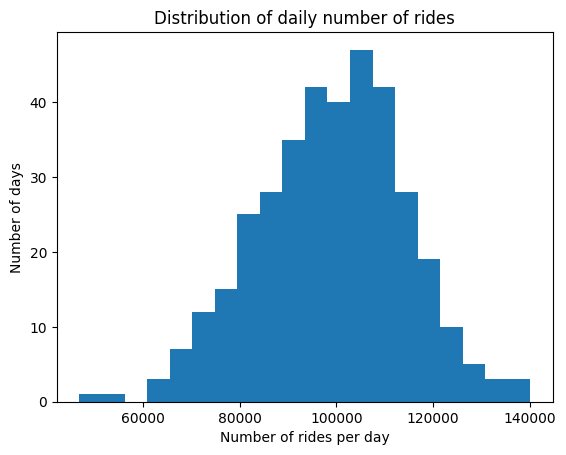

In [11]:
df.select("total_rides").to_pandas().plot.hist(
    bins=20,
    legend=False,
    title="Distribution of daily number of rides",
    xlabel="Number of rides per day",
    ylabel="Number of days",
)
plt.show()

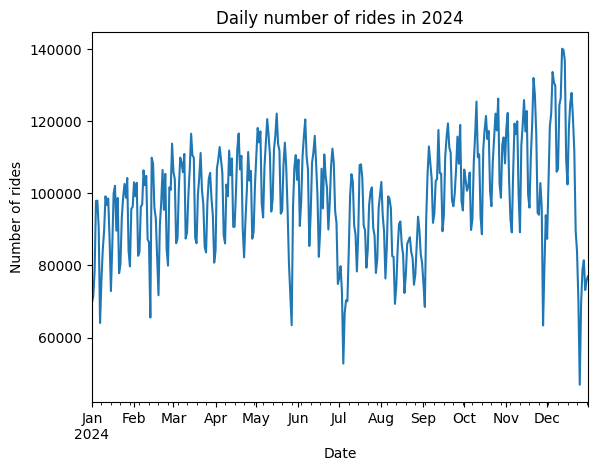

In [12]:
df.select("date", "total_rides").sort("date").to_pandas().plot.line(
    x="date",
    y="total_rides",
    legend=False,
    title="Daily number of rides in 2024",
    xlabel="Date",
    ylabel="Number of rides",
)
plt.show()